# 4 · The integrated cell: growth, division and cell-to-cell variation

`VirtualCell` advances all sub-models over one shared state (60 s steps, metabolism re-solved every 15 min).
A newborn G1 HeLa cell is started from the measured composition and left alone in reference medium.
Nothing in this notebook was fitted to cell-cycle data except three phase time constants (S ≈ 8 h, G2 ≈ 3 h,
M ≈ 1 h); G1 length, the doubling time and size homeostasis emerge from growth and the checkpoints.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from humancell import plotting as P; P.style()
from humancell.cell import VirtualCell
from humancell.experiments import run_many

cell = VirtualCell(stochastic=False)
cell.run(100)
h = cell.frame()
cell.summary()

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


{'alive': True,
 'fate': 'alive',
 'hours': 100.0,
 'divisions': 4,
 'phase': 'G1',
 'size': 0.8164102557919537,
 'growth': np.float64(0.02936263356910638),
 'mu_cap': 0.04113885501862186,
 'EC': 1.0,
 'p53': 0.9257589388307031,
 'dsb': 0.9927739904047858}

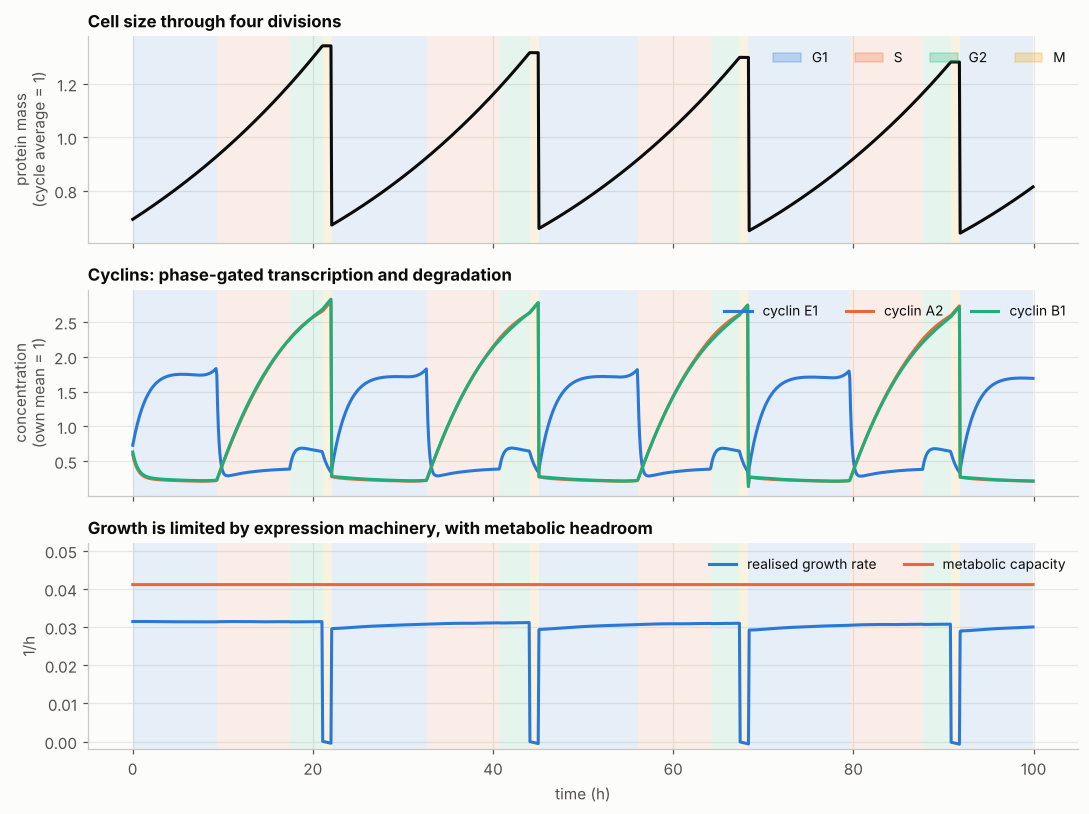

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
ax = axes[0]; handles, labels = P.phase_bands(ax, h)
ax.plot(h.t, h["size"], color=P.INK); ax.set_ylabel("protein mass\n(cycle average = 1)")
ax.set_title("Cell size through four divisions"); ax.legend(handles, labels, ncol=4, loc="upper right")
ax = axes[1]; P.phase_bands(ax, h)
for k, name in enumerate(["CCNE1", "CCNA2", "CCNB1"]):
    conc = h[f"p:{name}"] / h["size"]
    ax.plot(h.t, conc / conc.mean(), label={"CCNE1": "cyclin E1", "CCNA2": "cyclin A2", "CCNB1": "cyclin B1"}[name], color=P.SERIES[k])
ax.set_ylabel("concentration\n(own mean = 1)"); ax.set_title("Cyclins: phase-gated transcription and degradation"); ax.legend(ncol=3, loc="upper right")
ax = axes[2]; P.phase_bands(ax, h)
ax.plot(h.t, h.mu, color=P.SERIES[0], label="realised growth rate"); ax.plot(h.t, h.mu_cap, color=P.SERIES[1], label="metabolic capacity")
ax.set_ylabel("1/h"); ax.set_xlabel("time (h)"); ax.set_ylim(-0.002, 0.052); ax.set_title("Growth is limited by expression machinery, with metabolic headroom"); ax.legend(ncol=2, loc="upper right")
plt.tight_layout(); plt.show()

In [3]:
dur = h.groupby("phase").size() * (h.t.iloc[1] - h.t.iloc[0]) / max(len(cell.divisions), 1)
cyc = np.diff(cell.divisions)
bench = pd.DataFrame({
    "model": [f"{cyc.mean():.1f} h", f"{dur['G1']:.1f} h", f"{dur['S']:.1f} h", f"{dur['G2']:.1f} h", f"{dur['M']:.1f} h",
              f"{h['size'].max() / h['size'].min():.2f}×", f"{-h.q_glc.iloc[-1]:.2f}", f"{h.q_lac.iloc[-1]:.2f}", f"{h.Vm.mean():.0f} mV", f"{h.Ca.mean() * 1000:.0f} nM"],
    "HeLa literature": ["≈ 22 h", "8–11 h", "≈ 8 h (set)", "≈ 3 h (set)", "≈ 1 h (set)", "2×", "pinned at reference", "pinned at reference", "−40 to −60 mV", "≈ 100 nM (set)"],
}, index=["cell-cycle time (steady)", "G1", "S", "G2", "M", "size range over a cycle", "glucose uptake, mmol/gDW/h", "lactate secretion, mmol/gDW/h", "membrane potential", "cytosolic Ca²⁺"])
bench

,model,HeLa literature
cell-cycle time (steady),23.2 h,≈ 22 h
G1,12.6 h,8–11 h
S,8.1 h,≈ 8 h (set)
G2,3.3 h,≈ 3 h (set)
M,1.0 h,≈ 1 h (set)
size range over a cycle,2.09×,2×
"glucose uptake, mmol/gDW/h",0.65,pinned at reference
"lactate secretion, mmol/gDW/h",1.05,pinned at reference
membrane potential,-65 mV,−40 to −60 mV
cytosolic Ca²⁺,100 nM,≈ 100 nM (set)


## Stochastic cells
With `stochastic=True` every transcription, translation and degradation event is sampled, and molecules are
partitioned binomially at division. Eight independent cells, 110 hours each.

{'alive': 8} | cycle time 20.2 ± 3.5 h (n=36)


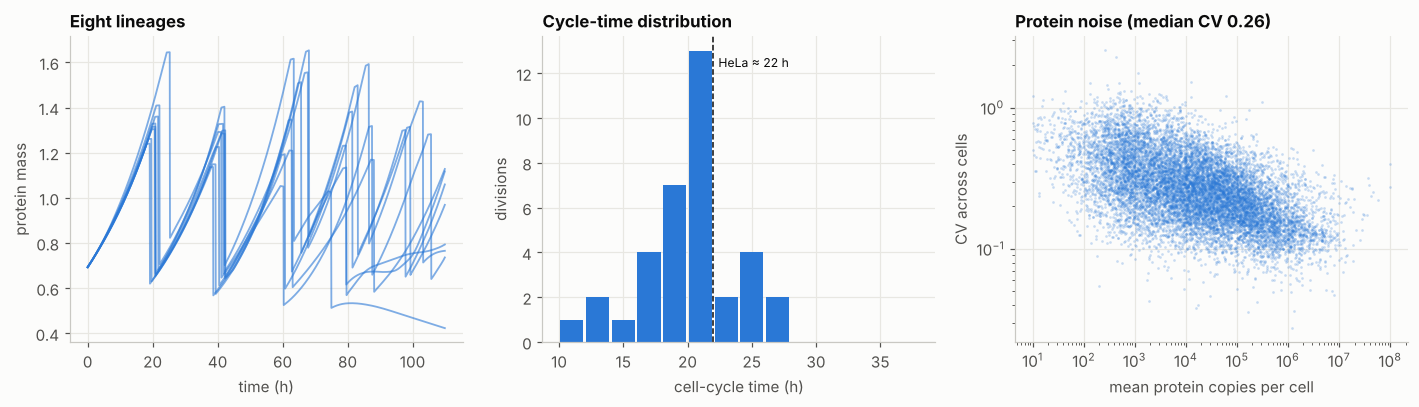

In [4]:
recipes = {f"cell {i}": [("init", (), {"seed": i, "stochastic": True}), ("run", (110,), {})] for i in range(8)}
pop = run_many(recipes, want=("protein",))
cycles = np.concatenate([np.diff([0] + r["divisions"]) for r in pop.values()])
fates = pd.Series([r["summary"]["fate"] for r in pop.values()]).value_counts()
print(fates.to_dict(), "| cycle time %.1f ± %.1f h (n=%d)" % (cycles.mean(), cycles.std(), len(cycles)))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
for k, (name, r) in enumerate(pop.items()):
    ax.plot(r["frame"].t, r["frame"]["size"], lw=1.2, color=P.SERIES[0], alpha=0.6)
ax.set_xlabel("time (h)"); ax.set_ylabel("protein mass"); ax.set_title("Eight lineages")
ax = axes[1]
ax.hist(cycles, bins=np.arange(10, 40, 2), color=P.SERIES[0], rwidth=0.9)
ax.axvline(22, color=P.INK, ls="--", lw=1); ax.text(22.4, ax.get_ylim()[1] * 0.9, "HeLa ≈ 22 h", fontsize=8)
ax.set_xlabel("cell-cycle time (h)"); ax.set_ylabel("divisions"); ax.set_title("Cycle-time distribution")
ax = axes[2]
Pm = np.array([r["protein"] / r["summary"]["size"] for r in pop.values() if r["summary"]["alive"]])
mean = Pm.mean(0); ok = mean > 10
cv = Pm.std(0)[ok] / mean[ok]
ax.scatter(mean[ok], cv, s=3, color=P.SERIES[0], alpha=0.25, linewidths=0)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("mean protein copies per cell"); ax.set_ylabel("CV across cells")
ax.set_title(f"Protein noise (median CV {np.median(cv):.2f})")
plt.tight_layout(); plt.show()

**What to take from this**

* The cell grows exponentially, replicates, divides and keeps doing so with a stable size, i.e. the coupled
  system has a self-reproducing steady state.
* Cycle times centre on the HeLa value. The spread (CV ≈ 20–25%) is somewhat wider than live-imaging data
  (CV ≈ 10–20%), and it comes only from molecular noise.
* Not every lineage is healthy: in most runs one or two of eight cells enter a long arrest (one keeps
  growing without dividing, one stops growing). Real HeLa cultures also contain a few percent of such cells,
  but the model's fraction is higher, which points to remaining over-sensitivity to low-copy noise.
* The resting membrane potential (−65 mV) is more negative than HeLa measurements (−40 to −60 mV): the
  pump-leak module uses generic permeabilities.
* Protein noise falls with abundance and floors at the level set by partitioning and low-copy mRNAs, the
  shape seen in single-cell proteomics. Measured CVs for mid-abundance human proteins are 0.15–0.3.

**Design lesson recorded during the build.** With strict Liebig limitation (every machine exactly as fast as
its scarcest subunit) the stochastic cell was not viable: random dips of low-copy subunits throttled
expression of everything. Viability required the reserve that real cells demonstrably have (essential genes
tolerate ~70–80% knock-down). Robustness to noise is a constraint on any whole-cell model, not an add-on.